In [11]:
import pandas as pd
import matplotlib.pyplot as plt

daily = pd.read_csv("../data/processed/daily_prices.csv", parse_dates=["date"])

print(daily.shape)
daily.head()

(1802, 4)


,date,price_mean,price_max,price_min
0,2021-11-01,0.505190,0.90065,0.10624
1,2021-11-02,0.648086,0.98402,0.03405
2,2021-11-03,0.715721,1.18299,0.14821
3,2021-11-04,0.796647,1.23847,0.17878
4,2021-11-05,0.576681,1.03983,0.07443


Det finns 1437 rader (dagar) 

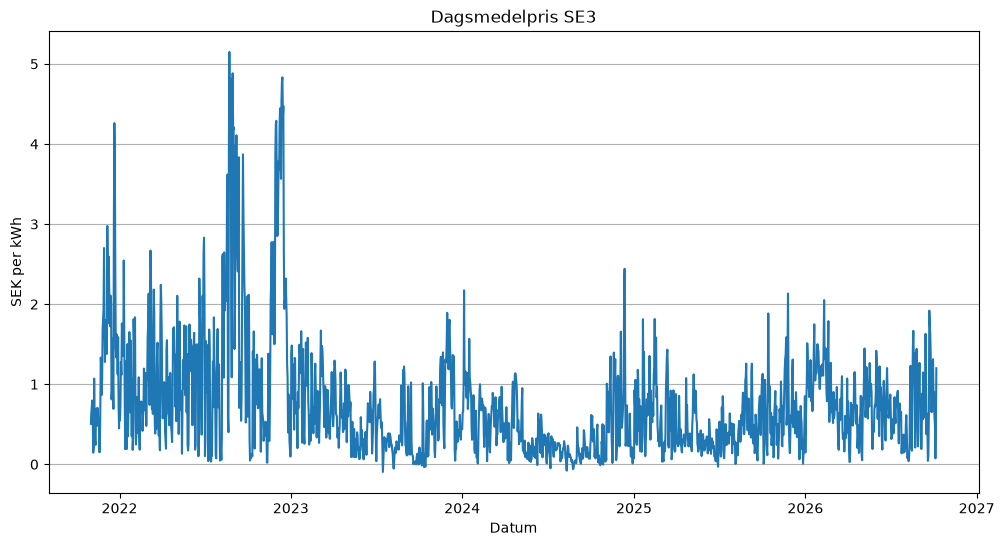

In [12]:
plt.figure(figsize=(12, 6))
plt.plot(daily["date"], daily["price_mean"])
plt.title("Dagsmedelpris SE3")
plt.xlabel("Datum")
plt.ylabel("SEK per kWh")
plt.grid(axis="y")
plt.show()

- I början av grafen är en stor avikelse där priset närmar sig 5
- 2021 - 2023 ligger högre än 2023 och frammåt

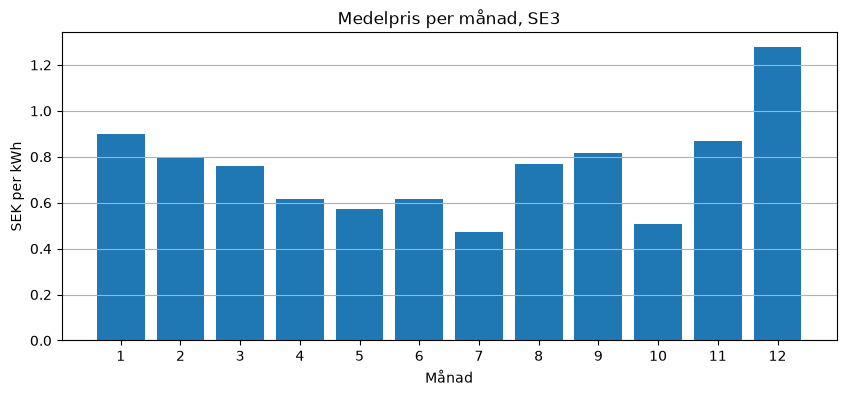

In [13]:
daily["month"] = daily["date"].dt.month

# Medelpris per kalendermånad, över alla år
monthly = daily.groupby("month")["price_mean"].mean()

plt.figure(figsize=(10, 4))
plt.bar(monthly.index, monthly.values)
plt.title("Medelpris per månad, SE3")
plt.xlabel("Månad")
plt.ylabel("SEK per kWh")
plt.xticks(range(1, 13))
plt.grid(axis="y")
plt.show()

- Vintermånaderna har högst pris där December är den dyraste månaden
- Alla månader utom December har ett medelpris på under 1kr per KwH
- Sommarmånaderna har lägst pris i genomsnitt där Juli har lägsta medelpris
- Resonabelt att månad ska vara en feature i modellen

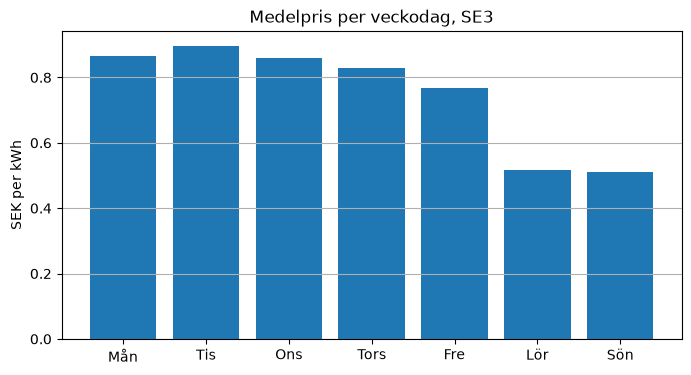

In [14]:
daily["weekday"] = daily["date"].dt.dayofweek

weekday = daily.groupby("weekday")["price_mean"].mean()

plt.figure(figsize=(8, 4))
plt.bar(["Mån", "Tis", "Ons", "Tors", "Fre", "Lör", "Sön"], weekday.values)
plt.title("Medelpris per veckodag, SE3")
plt.ylabel("SEK per kWh")
plt.grid(axis="y")
plt.show()

- Helger har lägre medelpriser än veckodagar
- Veckodagarna ligger nära varandra där tisdag har högst pris och fredag lägst pris av veckodagarna

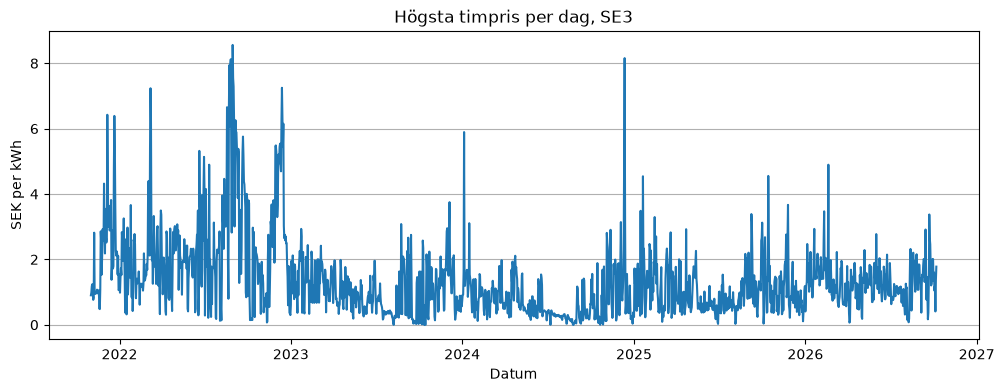

,date,price_mean,price_max
302,2022-08-30,4.883027,8.56048
1137,2024-12-12,2.441520,8.15709
298,2022-08-26,4.363023,8.12152
295,2022-08-23,5.149597,7.94391
297,2022-08-25,4.818430,7.90536
303,2022-08-31,4.177534,7.54563
304,2022-09-01,4.211458,7.29232
407,2022-12-13,4.785968,7.24947
127,2022-03-08,2.669008,7.23467
290,2022-08-18,3.393941,6.65496


In [15]:
plt.figure(figsize=(12, 4))
plt.plot(daily["date"], daily["price_max"])
plt.title("Högsta timpris per dag, SE3")
plt.xlabel("Datum")
plt.ylabel("SEK per kWh")
plt.grid(axis="y")
plt.show()

# De tio dagarna med högst toppris
daily.nlargest(10, "price_max")[["date", "price_mean", "price_max"]]

- grafen visar spikar i elpriser
- 9 av dom 10 högsta spikarna skedde 2022
- 2024-12-12 hade en hög spik men medelpriset är relativt lågt

In [16]:
# Dagar där lägsta timpriset var under noll
negative = daily[daily["price_min"] < 0]

print("Antal dagar med negativt pris:", len(negative))
print("Andel av alla dagar:", round(len(negative) / len(daily) * 100, 1), "%")

negative.groupby("month")["price_min"].count()

Antal dagar med negativt pris: 258
Andel av alla dagar: 14.3 %


month
1      7
2      6
3     13
4     23
5     47
6     30
7     17
8     26
9     29
10    39
11    11
12    10
Name: price_min, dtype: int64

- 258 eller 14.3% av alla dagar hade vid något tillfälle negativt pris
- Maj har flest dagar med negativt pris medan februari har minst antal
- Vintermånaderna verkar ha färre antal dagar med negativt pris än resten av året